In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
import warnings; warnings.filterwarnings("ignore")

REPO = Path(r"C:\Users\yaroo\pd-speech-detection")
df = pd.read_csv(REPO / "db" / "segment_features.csv")
pred = pd.read_csv(REPO / "model" / "results" / "svm_progress_report" / "out_of_fold_predictions.csv")
df["Group"] = df["PD"].map({0: "HC", 1: "PD"})
summary = df.groupby("Group")[FEATURES].agg(["mean", "std"]).T.round(3)
display(summary)
summary.to_csv(OUT / "feature_means_by_group.csv")

# Participant-level means avoid letting people with more segments dominate
pm = df.groupby(["participant_id", "Group"])[FEATURES].mean().reset_index()
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, f in zip(axes.flat, FEATURES):
    data = [pm.loc[pm.Group == g, f] for g in ["HC", "PD"]]
    ax.boxplot(data, labels=["HC", "PD"])
    ax.set_title(f)
fig.suptitle("Feature distributions by group (one point per participant)")
plt.tight_layout()
fig.savefig(OUT / "feature_boxplots_by_group.png", dpi=180, bbox_inches="tight")
plt.show()

print("Feature correlations:")
display(df[FEATURES].corr().round(2))
FEATURES = ["CPPS","HNR","Shimmer (local)","Shimmer (local_dB)","LTAS Slope","LTAS Tilt"]
OUT = REPO / "model" / "results" / "yara_analysis"
OUT.mkdir(parents=True, exist_ok=True)
print(df.shape, pred.shape)

(1013, 10) (1013, 7)


Group                        HC      PD
CPPS               mean   8.475   7.670
                   std    1.930   1.635
HNR                mean  12.266  12.142
                   std    3.136   3.160
Shimmer (local)    mean   0.104   0.114
                   std    0.038   0.039
Shimmer (local_dB) mean   1.009   1.093
                   std    0.296   0.287
LTAS Slope         mean -16.730 -19.964
                   std    3.913   4.873
LTAS Tilt          mean  -8.399  -7.692
                   std    2.617   2.746

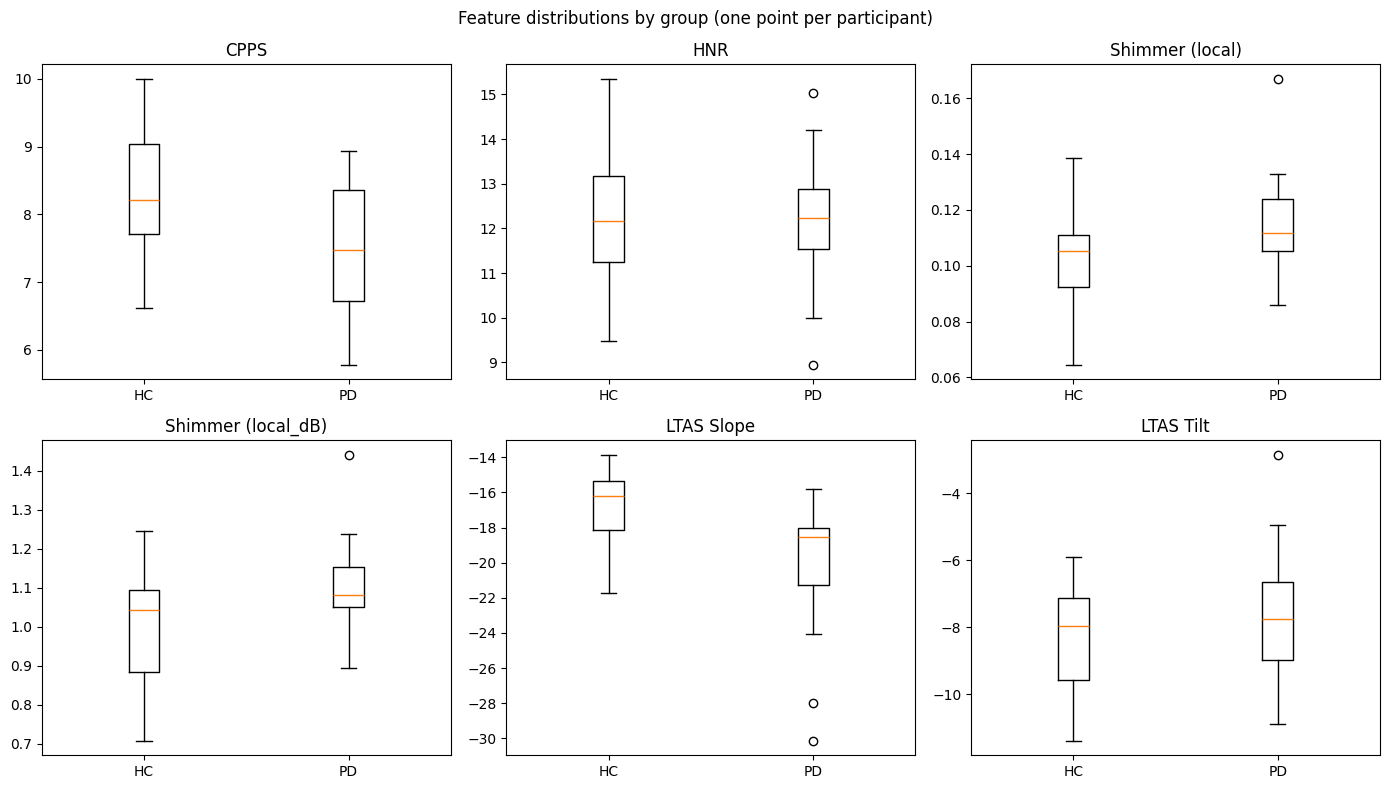

Feature correlations:


,CPPS,HNR,Shimmer (local),Shimmer (local_dB),LTAS Slope,LTAS Tilt
CPPS,1.00,0.60,-0.59,-0.64,0.33,-0.30
HNR,0.60,1.00,-0.87,-0.89,0.12,-0.17
Shimmer (local),-0.59,-0.87,1.00,0.96,-0.29,0.23
Shimmer (local_dB),-0.64,-0.89,0.96,1.00,-0.31,0.24
LTAS Slope,0.33,0.12,-0.29,-0.31,1.00,-0.30
LTAS Tilt,-0.30,-0.17,0.23,0.24,-0.30,1.00


In [2]:
df["Group"] = df["PD"].map({0: "HC", 1: "PD"})
summary = df.groupby("Group")[FEATURES].agg(["mean", "std"]).T.round(3)
display(summary)
summary.to_csv(OUT / "feature_means_by_group.csv")

# Participant-level means avoid letting people with more segments dominate
pm = df.groupby(["participant_id", "Group"])[FEATURES].mean().reset_index()
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, f in zip(axes.flat, FEATURES):
    data = [pm.loc[pm.Group == g, f] for g in ["HC", "PD"]]
    ax.boxplot(data, labels=["HC", "PD"])
    ax.set_title(f)
fig.suptitle("Feature distributions by group (one point per participant)")
plt.tight_layout()
fig.savefig(OUT / "feature_boxplots_by_group.png", dpi=180, bbox_inches="tight")
plt.show()

print("Feature correlations:")
display(df[FEATURES].corr().round(2))

In [3]:
# Majority vote of each participant's segment predictions
part = pred.groupby("participant_id").agg(
    true_PD=("true_PD", "first"),
    segments=("svm_prediction", "size"),
    frac_predicted_PD=("svm_prediction", "mean"),
).reset_index()
part["predicted_PD"] = (part["frac_predicted_PD"] >= 0.5).astype(int)
part["correct"] = part["predicted_PD"] == part["true_PD"]
display(part.round(2))

acc = part["correct"].mean()
tp = ((part.true_PD==1)&(part.predicted_PD==1)).sum()
tn = ((part.true_PD==0)&(part.predicted_PD==0)).sum()
print(f"Participant-level accuracy: {acc:.3f} ({part.correct.sum()}/{len(part)})")
print(f"PD correctly identified: {tp}/{(part.true_PD==1).sum()}")
print(f"HC correctly identified: {tn}/{(part.true_PD==0).sum()}")
part.to_csv(OUT / "participant_level_svm.csv", index=False)


,participant_id,true_PD,segments,frac_predicted_PD,predicted_PD,correct
0,0,0,27,0.59,1,False
1,1,0,27,0.00,0,True
2,2,1,34,0.38,0,False
3,3,0,29,0.31,0,True
4,4,1,26,0.00,0,False
5,5,0,29,0.03,0,True
6,6,1,31,0.48,0,False
7,7,1,35,0.63,1,True
8,8,0,27,0.11,0,True
9,9,0,26,0.12,0,True


Participant-level accuracy: 0.622 (23/37)
PD correctly identified: 7/16
HC correctly identified: 16/21


In [4]:
rows = []
for task, g in pred.groupby("task"):
    rows.append({
        "task": task,
        "segments": len(g),
        "accuracy": (g.svm_prediction == g.true_PD).mean(),
        "recall_PD": ((g.svm_prediction==1)&(g.true_PD==1)).sum() / (g.true_PD==1).sum(),
        "specificity_HC": ((g.svm_prediction==0)&(g.true_PD==0)).sum() / (g.true_PD==0).sum(),
    })
task_res = pd.DataFrame(rows).round(3)
display(task_res)
task_res.to_csv(OUT / "svm_by_task.csv", index=False)


,task,segments,accuracy,recall_PD,specificity_HC
0,RT,507,0.655,0.556,0.718
1,SD,506,0.634,0.400,0.815
